# Credit Default Prediction: Comparing 5 Machine-Learning Models with Bank-Style Model Validation

**Goal:** predict the probability that a personal-loan borrower defaults within 12 months (PD), compare a traditional WoE logistic scorecard with four machine-learning models, and validate them the way a bank's model validation team would.

**Data:** Lending Club accepted loans 2007–2018 (Kaggle, wordsforthewise), 2.26M loans.

**Key decisions**
- Target: bad = 1 if the loan reaches 90 days past due or is charged off within 12 months of issue (last payment date + 3 months).
- Development sample 2013–2015 (mort_acc not recorded before 2012); out-of-time test 2016–2017.
- Only information available on the application date is used as input (no leakage).
- Individual applications with positive income only.

## 1. Data and target definition
### 1.1 Locate the data file
Find where Kaggle stored the Lending Club file.

In [2]:
import os

# list every file attached to this notebook
for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/wordsforthewise/lending-club/rejected_2007_to_2018Q4.csv.gz
/kaggle/input/datasets/wordsforthewise/lending-club/accepted_2007_to_2018Q4.csv.gz
/kaggle/input/datasets/wordsforthewise/lending-club/accepted_2007_to_2018q4.csv/accepted_2007_to_2018Q4.csv
/kaggle/input/datasets/wordsforthewise/lending-club/rejected_2007_to_2018q4.csv/rejected_2007_to_2018Q4.csv


### 1.2 Load the data
Load the key columns and check how many loans are in each status.

In [3]:
import pandas as pd

PATH = "/kaggle/input/datasets/wordsforthewise/lending-club/accepted_2007_to_2018Q4.csv.gz"

cols = ["id", "loan_amnt", "issue_d", "loan_status", "last_pymnt_d", "grade"]
df = pd.read_csv(PATH, usecols=cols, low_memory=False)

print("Rows:", len(df))
print(df["loan_status"].value_counts())
print(df[["issue_d", "last_pymnt_d"]].dropna().head(3))

Rows: 2260701
loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40
Name: count, dtype: int64
    issue_d last_pymnt_d
0  Dec-2015     Jan-2019
1  Dec-2015     Jun-2016
2  Dec-2015     Jun-2017


### 1.3 Loan status by issue year
The data was extracted in March 2019, so most 2017–2018 loans are still running.

In [4]:
# 1. Turn text dates like "Dec-2015" into real dates
df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y", errors="coerce")
df["last_pymnt_d"] = pd.to_datetime(df["last_pymnt_d"], format="%b-%Y", errors="coerce")

print("Loans issued from", df["issue_d"].min().date(), "to", df["issue_d"].max().date())
print("Latest payment in file (snapshot date):", df["last_pymnt_d"].max().date())

# 2. Share of each status within each issue year
df["year"] = df["issue_d"].dt.year
tab = pd.crosstab(df["year"], df["loan_status"], normalize="index").round(3)
print(tab[["Fully Paid", "Current", "Charged Off"]])

Loans issued from 2007-06-01 to 2018-12-01
Latest payment in file (snapshot date): 2019-03-01
loan_status  Fully Paid  Current  Charged Off
year                                         
2007.0            0.342    0.000        0.075
2008.0            0.550    0.000        0.103
2009.0            0.781    0.000        0.112
2010.0            0.802    0.000        0.119
2011.0            0.848    0.000        0.152
2012.0            0.838    0.000        0.162
2013.0            0.844    0.000        0.156
2014.0            0.772    0.051        0.175
2015.0            0.712    0.103        0.180
2016.0            0.518    0.309        0.157
2017.0            0.293    0.590        0.088
2018.0            0.096    0.863        0.018


### 1.4 Why "Fully Paid vs Charged Off" is biased
Using only finished loans gives a default rate that depends on how old the loans are (resolution bias).

In [5]:
# keep only loans that have finished (paid off fully, or charged off)
done = df[df["loan_status"].isin(["Fully Paid", "Charged Off"])].copy()

# make a 0/1 column: 1 if charged off, 0 if fully paid
done["charged_off"] = (done["loan_status"] == "Charged Off").astype(int)

# average of a 0/1 column = share of 1s = default rate, for each year
print(done.groupby("year")["charged_off"].mean().round(3))

year
2007.0    0.179
2008.0    0.158
2009.0    0.126
2010.0    0.129
2011.0    0.152
2012.0    0.162
2013.0    0.156
2014.0    0.184
2015.0    0.202
2016.0    0.233
2017.0    0.231
2018.0    0.157
Name: charged_off, dtype: float64


### 1.5 12-month default definition
bad = 1 if the estimated default date (last payment + 3 months) is within 12 months of issue.

In [6]:
# 1. keep loans issued up to Dec-2017 (so all have a full 12-month window),
#    and drop the old "does not meet credit policy" loans
pop = df[(df["issue_d"] <= "2017-12-01")
         & (~df["loan_status"].str.startswith("Does not meet", na=False))].copy()

# 2. if a borrower never paid at all, treat the issue date as the last payment
last_pay = pop["last_pymnt_d"].fillna(pop["issue_d"])

# 3. months from issue to default = months to last payment + 3 missed payments
months_to_default = ((last_pay.dt.year - pop["issue_d"].dt.year) * 12
                     + (last_pay.dt.month - pop["issue_d"].dt.month) + 3)

# 4. bad = in a default status AND defaulted within 12 months
bad_status = pop["loan_status"].isin(["Charged Off", "Default", "Late (31-120 days)"])
pop["bad"] = (bad_status & (months_to_default <= 12)).astype(int)

# 5. number of loans and 12-month default rate by year
print(pop.groupby("year")["bad"].agg(["size", "mean"]).round(3))
print("Overall 12-month default rate:", round(pop["bad"].mean(), 4))

          size   mean
year                 
2007.0     251  0.024
2008.0    1562  0.038
2009.0    4716  0.042
2010.0   11536  0.030
2011.0   21721  0.036
2012.0   53367  0.037
2013.0  134814  0.032
2014.0  235629  0.034
2015.0  421095  0.040
2016.0  434407  0.047
2017.0  443579  0.044
Overall 12-month default rate: 0.0412


## 2. Features
### 2.1 Application-time features
Attach 28 fields known on the application date. Blanks often carry meaning (e.g. never late).

In [7]:
# information known at application time (allowed as model inputs)
feature_cols = [
    "loan_amnt", "term", "int_rate", "installment", "grade", "sub_grade",
    "emp_length", "home_ownership", "annual_inc", "verification_status",
    "purpose", "dti", "delinq_2yrs", "earliest_cr_line",
    "fico_range_low", "fico_range_high", "inq_last_6mths",
    "mths_since_last_delinq", "mths_since_last_record", "open_acc", "pub_rec",
    "revol_bal", "revol_util", "total_acc", "initial_list_status",
    "application_type", "mort_acc", "pub_rec_bankruptcies",
]

# keep only ID, dates and target in pop, then attach the borrower information
pop = pop[["id", "issue_d", "year", "loan_status", "last_pymnt_d", "bad"]]
feat = pd.read_csv(PATH, usecols=["id"] + feature_cols, low_memory=False)
pop = pop.merge(feat, on="id", how="left")

print("Shape:", pop.shape)
print()
print("Share missing (top 10):")
print(pop[feature_cols].isna().mean().sort_values(ascending=False).head(10).round(3))
print()
print(pop["application_type"].value_counts())

Shape: (1762677, 34)

Share missing (top 10):
mths_since_last_record    0.832
mths_since_last_delinq    0.500
emp_length                0.060
mort_acc                  0.027
revol_util                0.001
pub_rec_bankruptcies      0.000
dti                       0.000
inq_last_6mths            0.000
installment               0.000
int_rate                  0.000
dtype: float64

application_type
Individual    1710952
Joint App       51725
Name: count, dtype: int64


### 2.2 Cleaning and feature engineering
Convert text to numbers, create ratios (pti, loan-to-income, credit history length), check mort_acc by year.

In [8]:
import numpy as np

# --- 1. keep individual applications with positive income ---
# (joint applications combine two incomes: a different product)
pop = pop[(pop["application_type"] == "Individual") & (pop["annual_inc"] > 0)].copy()
pop = pop.drop(columns="application_type")

# --- 2. turn text into numbers ---
# " 36 months" -> 36
pop["term"] = pop["term"].str.extract(r"(\d+)")[0].astype(float)
# "10+ years" -> 10, "< 1 year" -> 0
pop["emp_length"] = (pop["emp_length"].str.replace("< 1 year", "0", regex=False)
                     .str.extract(r"(\d+)")[0].astype(float))
# sub-grade "A1".."G5" -> 1..35 (higher = riskier)
letter = pop["sub_grade"].str[0].map({g: i for i, g in enumerate("ABCDEFG")})
pop["sub_grade_num"] = letter * 5 + pop["sub_grade"].str[1].astype(int)
pop = pop.drop(columns="sub_grade")

# --- 3. new features a credit analyst would look at ---
ecl = pd.to_datetime(pop["earliest_cr_line"], format="%b-%Y", errors="coerce")
pop["credit_hist_months"] = ((pop["issue_d"].dt.year - ecl.dt.year) * 12
                             + (pop["issue_d"].dt.month - ecl.dt.month))
pop = pop.drop(columns="earliest_cr_line")

pop["fico"] = (pop["fico_range_low"] + pop["fico_range_high"]) / 2
pop = pop.drop(columns=["fico_range_low", "fico_range_high"])

pop["loan_to_income"] = pop["loan_amnt"] / pop["annual_inc"]
pop["pti"] = pop["installment"] * 12 / pop["annual_inc"]     # payment-to-income

pop["home_ownership"] = pop["home_ownership"].replace({"NONE": "OTHER", "ANY": "OTHER"})

# --- 4. checks ---
print("Shape:", pop.shape, "| default rate:", round(pop["bad"].mean(), 4))
print()
print(pop[["term", "emp_length", "sub_grade_num", "credit_hist_months",
           "fico", "loan_to_income", "pti"]].describe().round(2).T)
print()
print("mort_acc missing share by year:")
print(pop["mort_acc"].isna().groupby(pop["year"]).mean().round(3))

Shape: (1710952, 34) | default rate: 0.0412

                        count    mean    std    min     25%     50%     75%  \
term                1710952.0   42.70  10.77   36.0   36.00   36.00   60.00   
emp_length          1612877.0    6.02   3.68    0.0    3.00    6.00   10.00   
sub_grade_num       1710952.0   11.61   6.33    1.0    7.00   11.00   15.00   
credit_hist_months  1710952.0  197.62  91.25   36.0  136.00  179.00  244.00   
fico                1710952.0  698.13  31.53  627.0  672.00  692.00  712.00   
loan_to_income      1710952.0    0.21   0.11    0.0    0.12    0.20    0.29   
pti                 1710952.0    0.08   0.04    0.0    0.05    0.07    0.10   

                       max  
term                 60.00  
emp_length           10.00  
sub_grade_num        35.00  
credit_hist_months  999.00  
fico                847.50  
loan_to_income        1.20  
pti                   0.49  

mort_acc missing share by year:
year
2007.0    1.00
2008.0    1.00
2009.0    1.00
2010.0 

## 3. Sample design
Train = 70% of 2013–15, in-time test = 30% of 2013–15, out-of-time test = 2016–17.

In [9]:
from sklearn.model_selection import train_test_split

# development = 2013-2015, out-of-time test = 2016-2017
dev = pop[(pop["year"] >= 2013) & (pop["year"] <= 2015)]
oot = pop[pop["year"] >= 2016].copy()

# split development 70/30, keeping the same default rate in both parts
train, itt = train_test_split(dev, test_size=0.30, stratify=dev["bad"], random_state=42)
train, itt = train.copy(), itt.copy()

summary = pd.DataFrame({
    "loans": [len(train), len(itt), len(oot)],
    "default_rate": [train["bad"].mean(), itt["bad"].mean(), oot["bad"].mean()],
    "from": [s["issue_d"].min().date() for s in (train, itt, oot)],
    "to":   [s["issue_d"].max().date() for s in (train, itt, oot)],
}, index=["Train", "In-time test", "Out-of-time test"])
print(summary)

                   loans  default_rate        from          to
Train             553718      0.037118  2013-01-01  2015-12-01
In-time test      237309      0.037116  2013-01-01  2015-12-01
Out-of-time test  826772      0.045562  2016-01-01  2017-12-01


## 4. Weight of Evidence and Information Value
### 4.1 Worked example: FICO
WoE shows how much safer or riskier each group is than average; IV summarises the whole feature.

                   loans  bad_rate    woe     iv
fico                                            
(661.999, 667.0]  103193     0.050 -0.304  0.020
(667.0, 672.0]     51165     0.045 -0.201  0.004
(672.0, 677.0]     45327     0.044 -0.172  0.003
(677.0, 682.0]     44593     0.043 -0.153  0.002
(682.0, 687.0]     38986     0.041 -0.094  0.001
(687.0, 697.0]     71594     0.036  0.019  0.000
(697.0, 707.0]     57798     0.031  0.199  0.004
(707.0, 717.0]     44107     0.028  0.280  0.005
(717.0, 732.0]     41704     0.023  0.477  0.014
(732.0, 847.5]     55251     0.019  0.703  0.036

IV of FICO: 0.089


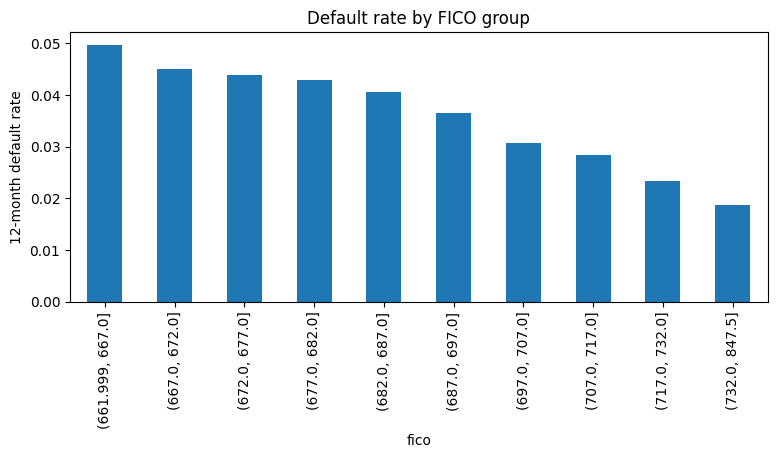

In [10]:
import numpy as np
import matplotlib.pyplot as plt

x = train["fico"]
y = train["bad"]

# 1. cut FICO into 10 equal-sized groups
groups = pd.qcut(x, q=10, duplicates="drop")

# 2. count loans and bads in each group
t = y.groupby(groups, observed=True).agg(["count", "sum"])
t.columns = ["loans", "bads"]
t["goods"] = t["loans"] - t["bads"]
t["bad_rate"] = t["bads"] / t["loans"]

# 3. WoE and IV
t["pct_good"] = t["goods"] / t["goods"].sum()
t["pct_bad"] = t["bads"] / t["bads"].sum()
t["woe"] = np.log(t["pct_good"] / t["pct_bad"])
t["iv"] = (t["pct_good"] - t["pct_bad"]) * t["woe"]

print(t[["loans", "bad_rate", "woe", "iv"]].round(3))
print("\nIV of FICO:", round(t["iv"].sum(), 3))

# 4. chart: default rate in each FICO group
t["bad_rate"].plot(kind="bar", figsize=(9, 3.5), title="Default rate by FICO group")
plt.ylabel("12-month default rate")
plt.show()

### 4.2 IV for all features
Rank all 28 features by IV. Features below 0.02 are not used in the scorecard.

sub_grade_num             0.537
grade                     0.520
int_rate                  0.502
fico                      0.088
inq_last_6mths            0.064
dti                       0.063
pti                       0.059
verification_status       0.054
loan_to_income            0.044
purpose                   0.043
home_ownership            0.040
annual_inc                0.038
credit_hist_months        0.038
term                      0.036
mort_acc                  0.032
emp_length                0.016
revol_bal                 0.014
revol_util                0.006
installment               0.005
initial_list_status       0.004
mths_since_last_record    0.004
total_acc                 0.003
mths_since_last_delinq    0.002
loan_amnt                 0.002
pub_rec                   0.001
pub_rec_bankruptcies      0.001
open_acc                  0.001
delinq_2yrs               0.000
dtype: float64

Sanity check, default rate by term:
            loans  bad_rate   woe
term              

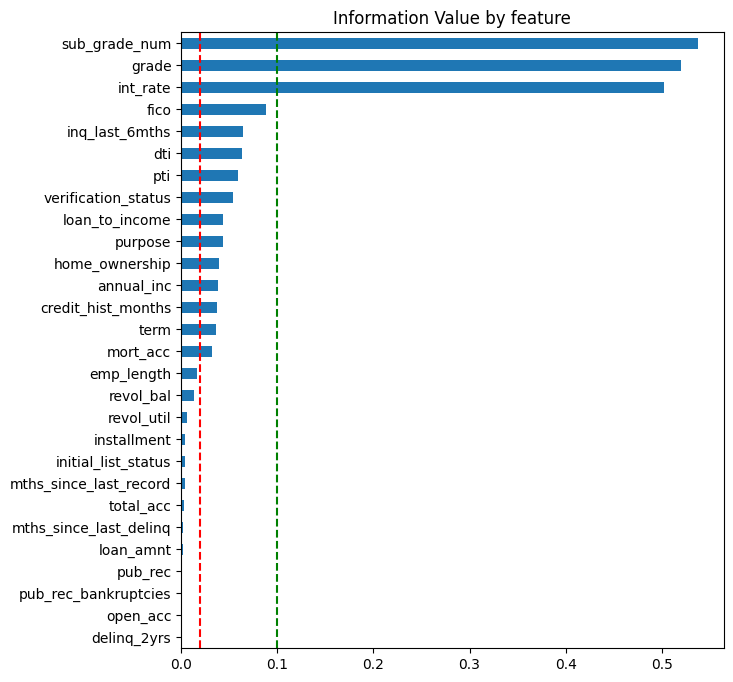

In [11]:
def woe_table(df, col, target="bad", q=10):
    """Default rate, WoE and IV for one feature (calculated on df)."""
    x = df[col]
    if pd.api.types.is_numeric_dtype(x):
        # cut points at the 10%, 20%, ... 90% positions (duplicates removed)
        inner = np.unique(x.quantile(np.linspace(0, 1, q + 1)[1:-1]))
        cuts = [-np.inf, *inner, np.inf]
        labels = [f"[{lo:g}, {hi:g})" for lo, hi in zip(cuts[:-1], cuts[1:])]
        codes = pd.cut(x, bins=cuts, right=False, labels=False)
        groups = codes.map(dict(enumerate(labels))).fillna("Missing")
        order = labels + ["Missing"]
    else:
        # text: each category is its own group
        groups = x.fillna("Missing")
        order = None

    t = df[target].groupby(groups).agg(["count", "sum"])
    t.columns = ["loans", "bads"]
    if order is not None:                      # keep groups in numeric order
        t = t.reindex([g for g in order if g in t.index])
    t["goods"] = t["loans"] - t["bads"]
    t["bad_rate"] = t["bads"] / t["loans"]
    t["pct_good"] = (t["goods"] + 0.5) / t["goods"].sum()
    t["pct_bad"] = (t["bads"] + 0.5) / t["bads"].sum()
    t["woe"] = np.log(t["pct_good"] / t["pct_bad"])
    t["iv"] = (t["pct_good"] - t["pct_bad"]) * t["woe"]
    return t

features = [
    "loan_amnt", "term", "int_rate", "installment", "grade", "sub_grade_num",
    "emp_length", "home_ownership", "annual_inc", "verification_status", "purpose",
    "dti", "delinq_2yrs", "fico", "inq_last_6mths", "mths_since_last_delinq",
    "mths_since_last_record", "open_acc", "pub_rec", "revol_bal", "revol_util",
    "total_acc", "initial_list_status", "mort_acc", "pub_rec_bankruptcies",
    "credit_hist_months", "loan_to_income", "pti",
]

tables = {c: woe_table(train, c) for c in features}
iv = pd.Series({c: t["iv"].sum() for c, t in tables.items()}).sort_values(ascending=False)
print(iv.round(3))

print("\nSanity check, default rate by term:")
print(tables["term"][["loans", "bad_rate", "woe"]].round(3))

iv.sort_values().plot(kind="barh", figsize=(7, 8), title="Information Value by feature")
plt.axvline(0.02, color="red", linestyle="--")
plt.axvline(0.10, color="green", linestyle="--")
plt.show()

## 5. Champion: WoE logistic scorecard
### 5.1 WoE transformation and correlation filter
Replace values with WoE, keep one version of the Lending Club grade, drop pairs with correlation above 0.6.

In [12]:
def to_woe(df, col, q=10):
    """Replace each value with the WoE of its group (groups and WoE learned on TRAIN)."""
    x = df[col]
    if pd.api.types.is_numeric_dtype(x):
        inner = np.unique(train[col].quantile(np.linspace(0, 1, q + 1)[1:-1]))
        cuts = [-np.inf, *inner, np.inf]
        labels = [f"[{lo:g}, {hi:g})" for lo, hi in zip(cuts[:-1], cuts[1:])]
        codes = pd.cut(x, bins=cuts, right=False, labels=False)
        groups = codes.map(dict(enumerate(labels))).fillna("Missing")
    else:
        groups = x.fillna("Missing")
    return groups.map(tables[col]["woe"]).astype(float).fillna(0.0)

# 1. candidates: IV >= 0.02, keeping only ONE version of Lending Club's grade
cand = [c for c in iv[iv >= 0.02].index if c not in ["grade", "int_rate"]]
print("Candidates:", len(cand), cand)

# 2. WoE version of each sample
W_train = pd.DataFrame({c: to_woe(train, c) for c in cand})
W_itt   = pd.DataFrame({c: to_woe(itt, c) for c in cand})
W_oot   = pd.DataFrame({c: to_woe(oot, c) for c in cand})
print("\nExample, first 3 train loans as WoE values:")
print(W_train.head(3).round(2))

# 3. pairs of features with correlation above 0.6
corr = W_train.corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().rename("corr").reset_index())
print("\nHighly correlated pairs (|corr| > 0.6):")
print(pairs[pairs["corr"].abs() > 0.6].sort_values("corr", ascending=False).round(2))

Candidates: 13 ['sub_grade_num', 'fico', 'inq_last_6mths', 'dti', 'pti', 'verification_status', 'loan_to_income', 'purpose', 'home_ownership', 'annual_inc', 'credit_hist_months', 'term', 'mort_acc']

Example, first 3 train loans as WoE values:
         sub_grade_num  fico  inq_last_6mths   dti   pti  verification_status  \
266137            0.32 -0.06           -0.44 -0.15 -0.02                -0.22   
1292219           0.14 -0.15           -0.10  0.04  0.12                 0.39   
1309226           1.30  0.41           -0.44  0.27  0.01                -0.03   

         loan_to_income  purpose  home_ownership  annual_inc  \
266137            -0.28    -0.05           -0.20       -0.33   
1292219            0.19    -0.05            0.21       -0.10   
1309226           -0.28    -0.05            0.21        0.02   

         credit_hist_months  term  mort_acc  
266137                -0.15 -0.26      0.11  
1292219                0.01  0.14      0.02  
1309226                0.28 -0.26   

### 5.2 Logistic regression
Check that all coefficients are negative, p-values are below 0.05 and VIF is below 5.

In [13]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

final = [c for c in cand if c not in ["loan_to_income", "mort_acc"]]
print("Scorecard features:", len(final), final)

# logistic regression on WoE features (train only)
X_tr = sm.add_constant(W_train[final])
logit = sm.Logit(train["bad"], X_tr).fit(disp=0)

coefs = logit.summary2().tables[1][["Coef.", "Std.Err.", "z", "P>|z|"]]
coefs["VIF"] = [np.nan] + [variance_inflation_factor(X_tr.values, i)
                           for i in range(1, X_tr.shape[1])]
print(coefs.round(4))
print("\nPseudo R-squared (McFadden):", round(logit.prsquared, 4))

Scorecard features: 11 ['sub_grade_num', 'fico', 'inq_last_6mths', 'dti', 'pti', 'verification_status', 'purpose', 'home_ownership', 'annual_inc', 'credit_hist_months', 'term']
                      Coef.  Std.Err.         z   P>|z|     VIF
const               -3.2592    0.0077 -423.3198  0.0000     NaN
sub_grade_num       -0.9013    0.0147  -61.2622  0.0000  2.1636
fico                -0.0409    0.0287   -1.4218  0.1551  1.3774
inq_last_6mths      -0.4737    0.0286  -16.5674  0.0000  1.0900
dti                 -0.5288    0.0293  -18.0345  0.0000  1.1268
pti                 -0.1945    0.0333   -5.8441  0.0000  1.3518
verification_status -0.2995    0.0341   -8.7878  0.0000  1.1327
purpose             -0.2058    0.0367   -5.6127  0.0000  1.1339
home_ownership      -0.6149    0.0385  -15.9756  0.0000  1.1236
annual_inc          -0.0650    0.0445   -1.4602  0.1442  1.4640
credit_hist_months  -0.4715    0.0390  -12.0912  0.0000  1.1301
term                 0.4026    0.0436    9.2271  0.0000

### 5.3 Final scorecard
Remove failing features one at a time (term dropped for wrong sign). Gini 0.42 on train and test.

In [14]:
from sklearn.metrics import roc_auc_score

feats = final.copy()
while True:
    m = sm.Logit(train["bad"], sm.add_constant(W_train[feats])).fit(disp=0)
    b = m.params.drop("const")
    p = m.pvalues.drop("const")
    if (b > 0).any():                       # 1st check: wrong sign
        drop = b.idxmax()
        reason = f"wrong sign (coef {b[drop]:+.3f})"
    elif (p > 0.05).any():                  # 2nd check: not significant
        drop = p.idxmax()
        reason = f"not significant (p = {p[drop]:.3f})"
    else:
        break                               # everything passes, stop
    print("Dropping", drop, "-", reason)
    feats.remove(drop)

scorecard = m
print("\nFinal scorecard features:", len(feats), feats)
print(scorecard.summary2().tables[1][["Coef.", "P>|z|"]].round(4))

# how well does it rank risk?
pd_train = scorecard.predict(sm.add_constant(W_train[feats]))
pd_itt   = scorecard.predict(sm.add_constant(W_itt[feats]))
print("\nGini, train        :", round(2 * roc_auc_score(train["bad"], pd_train) - 1, 4))
print("Gini, in-time test :", round(2 * roc_auc_score(itt["bad"], pd_itt) - 1, 4))

Dropping term - wrong sign (coef +0.403)

Final scorecard features: 10 ['sub_grade_num', 'fico', 'inq_last_6mths', 'dti', 'pti', 'verification_status', 'purpose', 'home_ownership', 'annual_inc', 'credit_hist_months']
                      Coef.   P>|z|
const               -3.2598  0.0000
sub_grade_num       -0.8372  0.0000
fico                -0.0941  0.0008
inq_last_6mths      -0.5129  0.0000
dti                 -0.5169  0.0000
pti                 -0.2001  0.0000
verification_status -0.2833  0.0000
purpose             -0.2692  0.0000
home_ownership      -0.6419  0.0000
annual_inc          -0.1461  0.0009
credit_hist_months  -0.4938  0.0000

Gini, train        : 0.42
Gini, in-time test : 0.4193


### 5.4 Points scaling
600 points at 50:1 odds, 20 points to double the odds.

Scorecard points, two example features:
      feature          group  loans  bad_rate  points
sub_grade_num      [-inf, 4)  41548     0.005     105
sub_grade_num         [4, 6)  47304     0.010      90
sub_grade_num         [6, 8)  58740     0.015      80
sub_grade_num        [8, 10)  67864     0.020      74
sub_grade_num       [10, 11)  29942     0.027      66
sub_grade_num       [11, 13)  66015     0.032      62
sub_grade_num       [13, 15)  64719     0.039      57
sub_grade_num       [15, 17)  50325     0.047      52
sub_grade_num       [17, 21)  64860     0.062      45
sub_grade_num      [21, inf)  62401     0.092      35
          dti   [-inf, 7.76)  55338     0.028      63
          dti  [7.76, 10.91)  55258     0.027      63
          dti [10.91, 13.42)  55409     0.029      62
          dti [13.42, 15.72)  55401     0.031      61
          dti    [15.72, 18)  55388     0.034      59
          dti    [18, 20.35)  55216     0.036      59
          dti [20.35, 22.97)  55561     0.

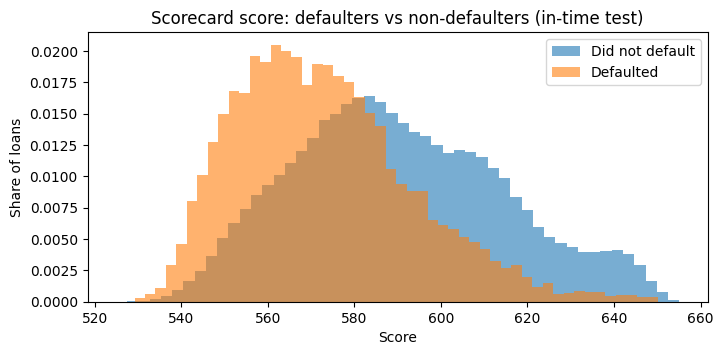

In [15]:
# --- 1. scaling constants ---
factor = 20 / np.log(2)                  # PDO = 20
offset = 600 - factor * np.log(50)       # 600 points at 50:1 odds
b = scorecard.params
n = len(feats)

# --- 2. points for every group of every feature ---
rows = []
for f in feats:
    for grp, r in tables[f].iterrows():
        pts = -factor * (b[f] * r["woe"] + b["const"] / n) + offset / n
        rows.append({"feature": f, "group": grp, "loans": int(r["loans"]),
                     "bad_rate": round(r["bad_rate"], 3), "points": round(pts)})
points = pd.DataFrame(rows)

print("Scorecard points, two example features:")
print(points[points["feature"].isin(["sub_grade_num", "dti"])].to_string(index=False))
lo = points.groupby("feature")["points"].min().sum()
hi = points.groupby("feature")["points"].max().sum()
print(f"\nLowest possible score: {lo}   Highest possible score: {hi}")

# --- 3. score every loan in the in-time test, compare goods vs bads ---
def score(W):
    log_odds_bad = b["const"] + (W[feats] * b[feats]).sum(axis=1)
    return offset - factor * log_odds_bad

score_itt = score(W_itt)
plt.figure(figsize=(8, 3.5))
plt.hist(score_itt[itt["bad"] == 0], bins=50, density=True, alpha=0.6, label="Did not default")
plt.hist(score_itt[itt["bad"] == 1], bins=50, density=True, alpha=0.6, label="Defaulted")
plt.xlabel("Score"); plt.ylabel("Share of loans"); plt.legend()
plt.title("Scorecard score: defaulters vs non-defaulters (in-time test)")
plt.show()

## 6. Challengers: machine-learning models
Decision tree, random forest, XGBoost and LightGBM on all 28 raw features. XGBoost chosen: tied with LightGBM but less overfitting.

In [16]:
import time
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

def gini(y, p):
    return 2 * roc_auc_score(y, p) - 1

# --- 1. prepare the data for ML models ---
cat_cols = ["grade", "home_ownership", "verification_status", "purpose", "initial_list_status"]

def make_X(df):
    X = pd.get_dummies(df[features], columns=cat_cols, dtype=float)  # text -> 0/1 columns
    return X.fillna(-1)                                              # blank -> -1

X_train = make_X(train)
X_itt = make_X(itt).reindex(columns=X_train.columns, fill_value=0)   # same columns as train
X_oot = make_X(oot).reindex(columns=X_train.columns, fill_value=0)
print("ML design matrix:", X_train.shape)

# --- 2. the four challengers ---
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=500, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=200,
                                            max_features=0.3, max_samples=0.5,
                                            n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4,
                             subsample=0.8, colsample_bytree=0.7,
                             tree_method="hist", n_jobs=-1, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31,
                               min_child_samples=500, subsample=0.8, subsample_freq=1,
                               colsample_bytree=0.7, n_jobs=-1, random_state=42, verbose=-1),
}

# --- 3. train each one and record Gini ---
pred_itt = {"Scorecard": pd_itt.values}
results = [{"model": "Scorecard", "gini_train": gini(train["bad"], pd_train),
            "gini_itt": gini(itt["bad"], pd_itt), "seconds": np.nan}]

for name, m in models.items():
    t0 = time.time()
    m.fit(X_train, train["bad"])
    p_tr = m.predict_proba(X_train)[:, 1]
    p_it = m.predict_proba(X_itt)[:, 1]
    pred_itt[name] = p_it
    results.append({"model": name, "gini_train": gini(train["bad"], p_tr),
                    "gini_itt": gini(itt["bad"], p_it), "seconds": time.time() - t0})
    print(f"{name} done in {time.time() - t0:.0f}s")

results = pd.DataFrame(results).set_index("model")
print(results.round(4).sort_values("gini_itt", ascending=False))

ML design matrix: (553718, 53)
Decision Tree done in 7s
Random Forest done in 115s
XGBoost done in 17s
LightGBM done in 22s
               gini_train  gini_itt   seconds
model                                        
LightGBM           0.5654    0.4509   22.0069
XGBoost            0.4950    0.4501   17.1553
Random Forest      0.4821    0.4354  115.3949
Scorecard          0.4200    0.4193       NaN
Decision Tree      0.4214    0.4102    7.4779


## 7. Out-of-time validation
Gini, KS, PR-AUC, Brier and calibration on 2016–17 loans. All models under-predict PD.

IN-TIME TEST (2013-2015)
                 Gini      KS  PR-AUC   Brier  Mean PD  Actual DR
LightGBM       0.4509  0.3336  0.0940  0.0348   0.0370     0.0371
XGBoost        0.4501  0.3321  0.0945  0.0347   0.0371     0.0371
Random Forest  0.4354  0.3227  0.0899  0.0348   0.0371     0.0371
Scorecard      0.4193  0.3105  0.0831  0.0349   0.0370     0.0371
Decision Tree  0.4102  0.3013  0.0817  0.0350   0.0370     0.0371

OUT-OF-TIME TEST (2016-2017)
                 Gini      KS  PR-AUC   Brier  Mean PD  Actual DR
XGBoost        0.4441  0.3225  0.1152  0.0422   0.0369     0.0456
LightGBM       0.4428  0.3211  0.1147  0.0422   0.0368     0.0456
Random Forest  0.4340  0.3146  0.1121  0.0423   0.0357     0.0456
Scorecard      0.4220  0.3058  0.1047  0.0425   0.0336     0.0456
Decision Tree  0.4084  0.2974  0.1025  0.0424   0.0370     0.0456


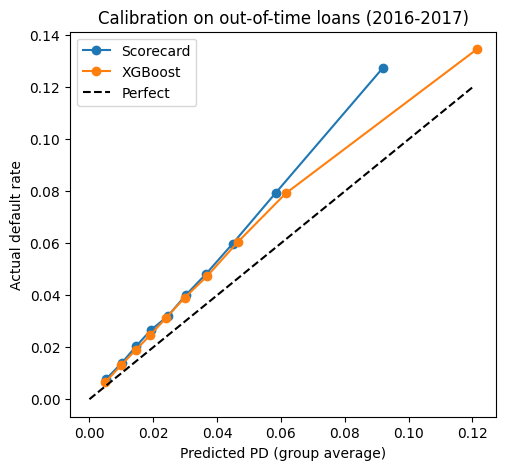


Share of 2016-17 loans with XGBoost PD > 0.5: 3e-05


In [17]:
from scipy.stats import ks_2samp
from sklearn.metrics import brier_score_loss, average_precision_score

# --- 1. PDs for the out-of-time loans (2016-2017) ---
pred_oot = {"Scorecard": scorecard.predict(sm.add_constant(W_oot[feats])).values}
for name, m in models.items():
    pred_oot[name] = m.predict_proba(X_oot)[:, 1]

# --- 2. the measures ---
def metrics(y, p):
    y, p = np.asarray(y), np.asarray(p)
    return {"Gini": gini(y, p),
            "KS": ks_2samp(p[y == 1], p[y == 0]).statistic,
            "PR-AUC": average_precision_score(y, p),
            "Brier": brier_score_loss(y, p),
            "Mean PD": p.mean(),
            "Actual DR": y.mean()}

comp_itt = pd.DataFrame({k: metrics(itt["bad"], v) for k, v in pred_itt.items()}).T
comp_oot = pd.DataFrame({k: metrics(oot["bad"], v) for k, v in pred_oot.items()}).T
print("IN-TIME TEST (2013-2015)")
print(comp_itt.sort_values("Gini", ascending=False).round(4))
print("\nOUT-OF-TIME TEST (2016-2017)")
print(comp_oot.sort_values("Gini", ascending=False).round(4))

# --- 3. calibration (reliability) chart: predicted vs actual, 10 groups ---
def calib(y, p):
    d = pd.DataFrame({"actual": np.asarray(y), "predicted": np.asarray(p)})
    d["group"] = pd.qcut(d["predicted"].rank(method="first"), 10, labels=False)
    return d.groupby("group")[["predicted", "actual"]].mean()

plt.figure(figsize=(5.5, 5))
for name in ["Scorecard", "XGBoost"]:
    c = calib(oot["bad"], pred_oot[name])
    plt.plot(c["predicted"], c["actual"], marker="o", label=name)
plt.plot([0, 0.12], [0, 0.12], "k--", label="Perfect")
plt.xlabel("Predicted PD (group average)")
plt.ylabel("Actual default rate")
plt.title("Calibration on out-of-time loans (2016-2017)")
plt.legend()
plt.show()

# --- 4. quick check: how many loans get PD above 0.5? ---
print("\nShare of 2016-17 loans with XGBoost PD > 0.5:",
      round((pred_oot["XGBoost"] > 0.5).mean(), 5))

## 8. Is the improvement significant?
200-sample paired bootstrap: XGBoost beats the scorecard by +0.022 Gini (95% CI 0.020 to 0.024).

In [18]:
y = oot["bad"].to_numpy()
names = list(pred_oot)
n, B = len(y), 200
rng = np.random.default_rng(42)

# --- 1. 200 resamples; every model is scored on the SAME resample ---
draws = {k: [] for k in names}
for b in range(B):
    idx = rng.integers(0, n, n)          # n random positions, with replacement
    for k in names:
        draws[k].append(gini(y[idx], pred_oot[k][idx]))
    if (b + 1) % 50 == 0:
        print(f"{b + 1} of {B} resamples done")
draws = pd.DataFrame(draws)

# --- 2. Gini with 95% confidence interval for each model ---
boot = pd.DataFrame({
    "Gini": {k: gini(y, pred_oot[k]) for k in names},
    "CI low": draws.quantile(0.025),
    "CI high": draws.quantile(0.975),
})

# --- 3. difference vs the scorecard, with its 95% interval ---
diff = draws.sub(draws["Scorecard"], axis=0)
boot["Diff vs Scorecard"] = boot["Gini"] - boot.loc["Scorecard", "Gini"]
boot["Diff CI low"] = diff.quantile(0.025)
boot["Diff CI high"] = diff.quantile(0.975)
print(boot.sort_values("Gini", ascending=False).round(4))

# --- 4. are XGBoost and LightGBM really different? ---
d = draws["XGBoost"] - draws["LightGBM"]
print(f"\nXGBoost - LightGBM: {d.mean():+.4f}  "
      f"95% CI [{d.quantile(0.025):+.4f}, {d.quantile(0.975):+.4f}]")

50 of 200 resamples done
100 of 200 resamples done
150 of 200 resamples done
200 of 200 resamples done
                 Gini  CI low  CI high  Diff vs Scorecard  Diff CI low  \
XGBoost        0.4441  0.4392   0.4490             0.0221       0.0201   
LightGBM       0.4428  0.4381   0.4479             0.0208       0.0184   
Random Forest  0.4340  0.4290   0.4388             0.0120       0.0103   
Scorecard      0.4220  0.4176   0.4270             0.0000       0.0000   
Decision Tree  0.4084  0.4036   0.4136            -0.0136      -0.0156   

               Diff CI high  
XGBoost              0.0240  
LightGBM             0.0226  
Random Forest        0.0137  
Scorecard            0.0000  
Decision Tree       -0.0109  

XGBoost - LightGBM: +0.0013  95% CI [+0.0004, +0.0023]


## 9. Stability (PSI)
The applicant population was stable (PSI below 0.03), yet defaults rose, so back-testing is needed, not just PSI.

In [19]:
# --- 1. PSI function: 10 bands based on 2013-15 (train) PDs ---
def psi(expected, actual, bins=10):
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected)   # old share per band
    a = np.histogram(actual, edges)[0] / len(actual)       # new share per band
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)  # avoid log(0)
    return float(np.sum((a - e) * np.log(a / e))), e, a

# --- 2. PDs on the train loans (2013-15) for every model ---
pred_train = {"Scorecard": pd_train.values}
for name, m in models.items():
    pred_train[name] = m.predict_proba(X_train)[:, 1]

# --- 3. score PSI for every model ---
score_psi = pd.Series({k: psi(pred_train[k], pred_oot[k])[0] for k in pred_oot},
                      name="Score PSI").sort_values()
print(score_psi.round(4))

# --- 4. the band table for XGBoost, so you can see the shift ---
val, e, a = psi(pred_train["XGBoost"], pred_oot["XGBoost"])
bands = pd.DataFrame({"2013-15 share": e, "2016-17 share": a,
                      "contribution": (a - e) * np.log(a / e)},
                     index=[f"Band {i+1}" for i in range(len(e))])
print("\nXGBoost PD bands (Band 1 = safest, Band 10 = riskiest):")
print(bands.round(4))

# --- 5. CSI: which scorecard feature shifted? ---
def psi_groups(old, new):
    po = old.value_counts(normalize=True)
    pn = new.value_counts(normalize=True)
    idx = po.index.union(pn.index)
    po = po.reindex(idx, fill_value=0).clip(lower=1e-6)
    pn = pn.reindex(idx, fill_value=0).clip(lower=1e-6)
    return float(((pn - po) * np.log(pn / po)).sum())

csi = pd.Series({f: psi_groups(W_train[f].round(6), W_oot[f].round(6)) for f in feats},
                name="CSI").sort_values(ascending=False)
print("\nCSI by scorecard feature:")
print(csi.round(4))

LightGBM         0.0075
XGBoost          0.0087
Random Forest    0.0129
Decision Tree    0.0167
Scorecard        0.0214
Name: Score PSI, dtype: float64

XGBoost PD bands (Band 1 = safest, Band 10 = riskiest):
         2013-15 share  2016-17 share  contribution
Band 1             0.1         0.1154        0.0022
Band 2             0.1         0.0955        0.0002
Band 3             0.1         0.0995        0.0000
Band 4             0.1         0.1045        0.0002
Band 5             0.1         0.1087        0.0007
Band 6             0.1         0.1080        0.0006
Band 7             0.1         0.1020        0.0000
Band 8             0.1         0.0946        0.0003
Band 9             0.1         0.0843        0.0027
Band 10            0.1         0.0873        0.0017

CSI by scorecard feature:
pti                    0.0422
purpose                0.0396
sub_grade_num          0.0319
verification_status    0.0185
inq_last_6mths         0.0168
fico                   0.0160
annual_inc  

## 10. Explainability (SHAP)
XGBoost uses the same main drivers as the scorecard; extra power comes from interactions. Borrower-level reason codes.

Feature importance (NaN = not in the scorecard):
                        XGBoost rank  XGBoost mean |SHAP|  \
sub_grade_num                      1                0.488   
dti                                2                0.137   
int_rate                           3                0.127   
home_ownership                     4                0.097   
revol_util                         5                0.081   
fico                               6                0.073   
inq_last_6mths                     7                0.072   
term                               8                0.067   
mths_since_last_delinq             9                0.067   
emp_length                        10                0.066   
credit_hist_months                11                0.061   
total_acc                         12                0.054   
revol_bal                         13                0.048   
verification_status               14                0.047   
open_acc                          15

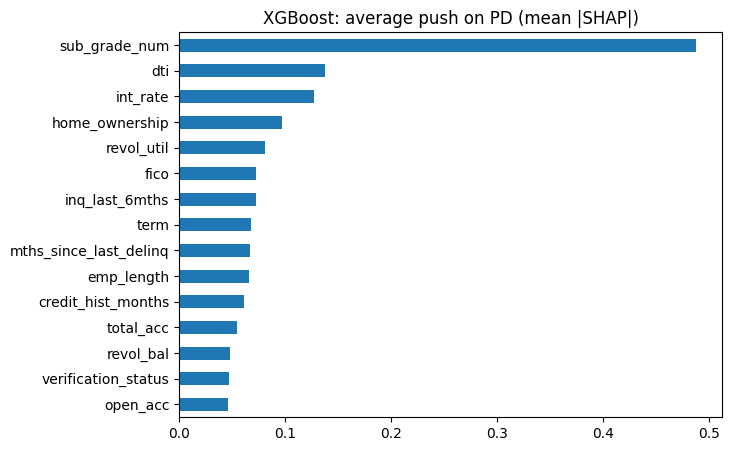


This borrower's PD: 12.3%   |   average borrower: 3.7%
Top 5 reasons pushing PD UP:
                borrower's value  push (log-odds)
sub_grade_num          22.000000            0.539
inq_last_6mths          3.000000            0.321
revol_bal          166349.000000            0.241
pti                     0.211517            0.149
dti                    31.250000            0.147


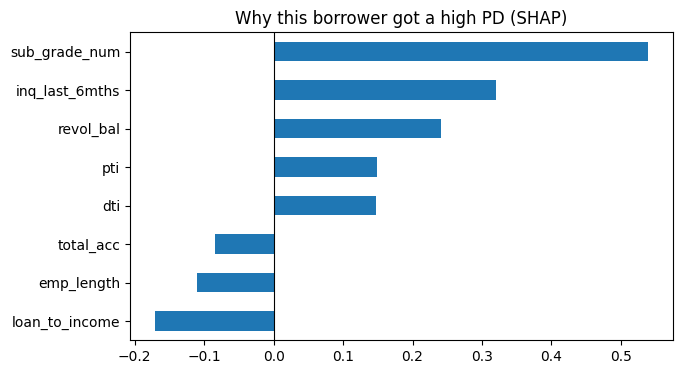

In [20]:
import xgboost as xgb

# --- 1. SHAP values for 5,000 random 2016-17 borrowers ---
xgb_model = models["XGBoost"]
rng = np.random.default_rng(42)
idx = rng.choice(len(X_oot), 5000, replace=False)
X_s = X_oot.iloc[idx]

contrib = xgb_model.get_booster().predict(xgb.DMatrix(X_s), pred_contribs=True)
shap_vals = pd.DataFrame(contrib[:, :-1], columns=X_s.columns, index=X_s.index)
base_value = contrib[0, -1]          # starting point = average borrower (log-odds)

# add the 0/1 columns back together (purpose_car + purpose_other + ... = purpose)
def base_feature(col):
    for c in cat_cols:
        if col.startswith(c + "_"):
            return c
    return col
shap_feat = shap_vals.T.groupby(base_feature).sum().T

# --- 2. overall importance: XGBoost (SHAP) vs scorecard (points range) ---
importance = shap_feat.abs().mean().sort_values(ascending=False)
sc_range = points.groupby("feature")["points"].agg(lambda s: s.max() - s.min())
compare = pd.DataFrame({
    "XGBoost rank": importance.rank(ascending=False).astype(int),
    "XGBoost mean |SHAP|": importance.round(3),
    "Scorecard points range": sc_range,
}).sort_values("XGBoost rank")
print("Feature importance (NaN = not in the scorecard):")
print(compare.head(15))

importance.head(15).sort_values().plot(kind="barh", figsize=(7, 5),
                                       title="XGBoost: average push on PD (mean |SHAP|)")
plt.show()

# --- 3. one high-risk 2016-17 borrower who really defaulted ---
p = xgb_model.predict_proba(X_s)[:, 1]
y_s = oot["bad"].to_numpy()[idx]
i = np.flatnonzero((p >= np.quantile(p, 0.9)) & (y_s == 1))[0]
row = shap_feat.iloc[i].sort_values(ascending=False)
borrower = oot.iloc[idx[i]]

print(f"\nThis borrower's PD: {p[i]:.1%}   |   average borrower: {1/(1+np.exp(-base_value)):.1%}")
top = row.head(5)
print("Top 5 reasons pushing PD UP:")
print(pd.DataFrame({"borrower's value": [borrower[f] for f in top.index],
                    "push (log-odds)": top.round(3)}))

pd.concat([row.head(5), row.tail(3)]).sort_values().plot(
    kind="barh", figsize=(7, 4), title="Why this borrower got a high PD (SHAP)")
plt.axvline(0, color="black", linewidth=0.8)
plt.show()

## 11. Business impact
At 80% approval, XGBoost approves 576 fewer defaulters than the scorecard (about $4.9M less loss). Accuracy is misleading.

APPROVE 80%, 2016-17 loans:
                       Bad rate of approved  Defaulters approved  Defaulters rejected  Actual loss ($M)  Predicted loss ($M)  Precision  Recall      F1  Accuracy
XGBoost                              0.0302              19986.0              17683.0          253.0002             184.7112     0.1069  0.4694  0.1742    0.7972
LightGBM                             0.0303              20048.0              17621.0          253.9376             181.7843     0.1066  0.4678  0.1736    0.7971
Random Forest                        0.0306              20231.0              17438.0          253.0087             191.6882     0.1055  0.4629  0.1718    0.7966
Scorecard                            0.0311              20562.0              17107.0          257.9249             186.6185     0.1035  0.4541  0.1685    0.7958
Decision Tree                        0.0323              21599.0              16070.0          273.3025             198.8334     0.1019  0.4266  0.1645    0.8025


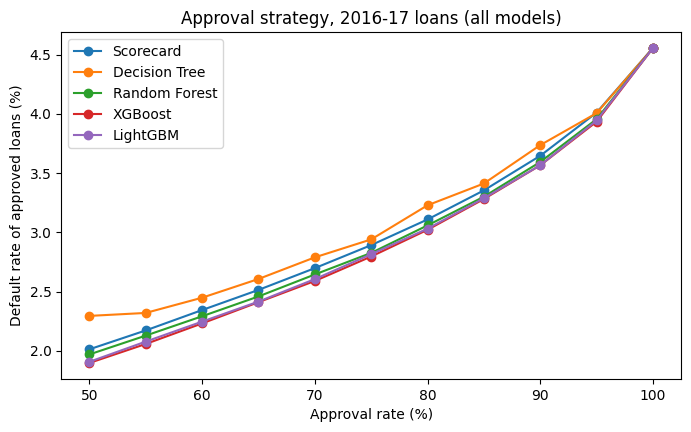

In [22]:
LGD = 0.85                                  # assumption: 85% of a defaulted loan is lost
y = oot["bad"].to_numpy()
amt = oot["loan_amnt"].to_numpy()

# --- 1. approve the 80% with the lowest PD, reject the riskiest 20% ---
def at_cutoff(p, approve_rate=0.80):
    p = np.asarray(p)
    approve = p <= np.quantile(p, approve_rate)
    reject = ~approve
    tp = int((reject & (y == 1)).sum())     # defaulter rejected  (caught)
    fp = int((reject & (y == 0)).sum())     # good customer rejected (lost business)
    fn = int((approve & (y == 1)).sum())    # defaulter approved  (money lost)
    tn = int((approve & (y == 0)).sum())    # good customer approved
    precision, recall = tp / (tp + fp), tp / (tp + fn)
    return {"Bad rate of approved": y[approve].mean(),
            "Defaulters approved": fn,
            "Defaulters rejected": tp,
            "Actual loss ($M)": amt[approve & (y == 1)].sum() * LGD / 1e6,
            "Predicted loss ($M)": (p[approve] * amt[approve]).sum() * LGD / 1e6,
            "Precision": precision, "Recall": recall,
            "F1": 2 * precision * recall / (precision + recall),
            "Accuracy": (tp + tn) / len(y),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}

biz = pd.DataFrame({k: at_cutoff(v) for k, v in pred_oot.items()}).T

# --- 2. baseline: no model, reject a random 20% ---
dr = y.mean()
biz.loc["No model (random 80%)"] = {
    "Bad rate of approved": dr, "Defaulters approved": round(0.8 * y.sum()),
    "Defaulters rejected": round(0.2 * y.sum()),
    "Actual loss ($M)": 0.8 * amt[y == 1].sum() * LGD / 1e6, "Predicted loss ($M)": np.nan,
    "Precision": dr, "Recall": 0.2, "F1": 2 * dr * 0.2 / (dr + 0.2),
    "Accuracy": 0.8 * (1 - dr) + 0.2 * dr, "TP": np.nan, "FP": np.nan, "FN": np.nan, "TN": np.nan}

print("APPROVE 80%, 2016-17 loans:")
print(biz.drop(columns=["TP", "FP", "FN", "TN"]).sort_values("Bad rate of approved").round(4).to_string())

# --- 3. confusion matrix for EVERY model ---
for name in pred_oot:
    r_ = biz.loc[name]
    cm = pd.DataFrame([[r_["TN"], r_["FP"]], [r_["FN"], r_["TP"]]],
                      index=["Actually good", "Actually bad"],
                      columns=["Approved", "Rejected"]).astype(int)
    print(f"\nConfusion matrix - {name}:")
    print(cm)

# --- 4. every model compared with the scorecard ---
print("\nCompared with the Scorecard:")
for name in pred_oot:
    if name == "Scorecard":
        continue
    d = biz.loc["Scorecard"] - biz.loc[name]
    print(f"{name:<14}: {int(d['Defaulters approved']):>+6,} fewer defaulters approved, "
          f"${d['Actual loss ($M)']:+.1f}M less loss")

# --- 5. bad rate at every approval rate from 50% to 100%, ALL models ---
rates = np.linspace(0.5, 1.0, 11)
plt.figure(figsize=(8, 4.5))
for name in pred_oot:
    p = np.asarray(pred_oot[name])
    plt.plot(rates * 100, [y[p <= np.quantile(p, rate)].mean() * 100 for rate in rates],
             marker="o", label=name)
plt.xlabel("Approval rate (%)"); plt.ylabel("Default rate of approved loans (%)")
plt.title("Approval strategy, 2016-17 loans (all models)"); plt.legend()
plt.show()

## 12. Final model comparison
All five models compared on every criterion.

In [23]:
names = list(pred_oot)   # the 5 models

matrix = pd.DataFrame({
    "Gini train":              results["gini_train"],
    "Gini in-time":            comp_itt["Gini"],
    "Overfit gap":             results["gini_train"] - comp_itt["Gini"],
    "Gini out-of-time":        comp_oot["Gini"],
    "Gini OOT 95% CI":         boot.apply(lambda r: f"{r['CI low']:.3f}-{r['CI high']:.3f}", axis=1),
    "Diff vs Scorecard":       boot["Diff vs Scorecard"],
    "KS (OOT)":                comp_oot["KS"],
    "PR-AUC (OOT)":            comp_oot["PR-AUC"],
    "Predicted / actual DR":   comp_oot["Mean PD"] / comp_oot["Actual DR"],
    "Score PSI":               score_psi,
    "Bad rate at 80% approval": biz["Bad rate of approved"],
    "Defaulters approved":     biz["Defaulters approved"],
    "Loss at 80% ($M)":        biz["Actual loss ($M)"],
    "F1 at 80%":               biz["F1"],
    "Accuracy at 80%":         biz["Accuracy"],
    "Training time (s)":       results["seconds"],
}).loc[names]

matrix["Explainability"] = pd.Series({
    "Scorecard": "High (points)", "Decision Tree": "Medium (one tree)",
    "Random Forest": "Low (SHAP)", "XGBoost": "Low (SHAP)", "LightGBM": "Low (SHAP)"})

matrix = matrix.round(3).sort_values("Gini out-of-time", ascending=False)
print(matrix.T.to_string())                      # criteria as rows, models as columns
matrix.to_csv("model_comparison.csv")            # saved for your README

                              XGBoost     LightGBM Random Forest      Scorecard      Decision Tree
Gini train                      0.495        0.565         0.482           0.42              0.421
Gini in-time                     0.45        0.451         0.435          0.419               0.41
Overfit gap                     0.045        0.114         0.047          0.001              0.011
Gini out-of-time                0.444        0.443         0.434          0.422              0.408
Gini OOT 95% CI           0.439-0.449  0.438-0.448   0.429-0.439    0.418-0.427        0.404-0.414
Diff vs Scorecard               0.022        0.021         0.012            0.0             -0.014
KS (OOT)                        0.322        0.321         0.315          0.306              0.297
PR-AUC (OOT)                    0.115        0.115         0.112          0.105              0.103
Predicted / actual DR           0.809        0.808         0.783          0.737              0.813
Score PSI 

## 13. Conclusion and recommendation

Five models were compared on 826,772 out-of-time loans (2016–17). **XGBoost performed best on every performance measure**: Gini 0.444 vs 0.422 for the WoE scorecard, the highest KS (0.322) and PR-AUC (0.115), and a very stable score distribution (PSI 0.009). A 200-sample paired bootstrap showed the improvement is statistically significant (+0.022 Gini, 95% CI 0.020 to 0.024). At an 80% approval rate, XGBoost approved 576 fewer defaulters than the scorecard, about **$4.9M lower loss** (around 2%, assuming 85% LGD). LightGBM performed almost identically but showed much stronger overfitting, and a single decision tree performed worse than the scorecard.

However, **all models under-predicted default risk on 2016–17 loans**: predicted PD was only 74–81% of the actual default rate. The applicant population looked stable (PSI below 0.03), but the default rate rose from 3.7% to 4.6%, so the deterioration was not visible in application data. **Any model used would need recalibration** and regular back-testing of predicted vs actual defaults, not only PSI monitoring.

**Recommendation:** keep the WoE scorecard as the champion model. XGBoost's improvement is real but modest, while the scorecard is fully transparent and every decision can be explained with points. XGBoost should run in parallel as a challenger, using SHAP-based reason codes, and replace the scorecard only if its advantage holds over the next 6–12 months. Both models should be recalibrated to the current default rate before use.